In [1]:
path_to_dodem = '/Users/jmdunca2/do-dem/'
from sys import path as sys_path
sys_path.append(path_to_dodem+'/dodem/')

import all_nu_analysis as ana
import visualize_dem_results as viz

import pickle
import numpy as np
from matplotlib import pyplot as plt
import importlib

with open('/Users/jmdunca2/do-dem/reference_files/all_targets_postghost_postshut.pickle', 'rb') as f:
    all_targets = pickle.load(f)

with open('/Users/jmdunca2/do-dem/reference_files/samesames.pickle', 'rb') as f:
    data = pickle.load(f)

samesames = data['same region lists']
grf = data['ghost ray flags']

def mod_timestring(timestring):
    modts=(':').join(timestring.split('-'))
    modts=('-').join(modts.split('_'))
    return modts

In [2]:
filelist = ana.get_same_region_file_lists(samesames, all_targets)

filelist_x = ana.get_same_region_file_lists(samesames, all_targets, noxrt=True)


In [ ]:

xrtkeys = ['29-may-18_1', '12-apr-19', '13-apr-19', '29-jan-20', 
           '29-apr-21', '14-jan-21', '3-may-21_2', '30-jul-21_1', '30-jul-21_2', '17-nov-21_1']


In [ ]:
#Looking at how inclusion of XRT effects the values of the peak EM or T

import os
import glob

maxs=[]
maxts=[]
filepairs = []
for f in filelist:
    f.sort()
    fnum=0
    for f_ in f:
        with open(f_, 'rb') as f:
            data = pickle.load(f)
        if len(data['dn_in']) > 9:
            fnum+=1
            #print(f_)
            stem = f_.split('/')[-1].split('_')[0:-4]
            sj = ('_').join(stem)
            #print(sj)
            res = glob.glob(os.path.dirname(f_)+'/'+sj+'*no_xrt*.pickle')
            #print(res)
            res.sort()
            if res:
                filepairs.append([res[1], f_])
                with open(res[1], 'rb') as f:
                    data2 = pickle.load(f)
                #print(data2.keys())
                maxs.append(np.array([data2['max'], data['max']]))
                maxts.append(np.array([data2['max_temp'], data['max_temp']]))

    #to print filenames of XRT-including DEM solutions
    #if fnum > 0:
        #print(fnum, f_)
    
fig = plt.figure(figsize=(5,5))
plt.hist(np.array(maxs)[:,0]/np.array(maxs)[:,1])  
plt.title('No XRT max / All-inst max')

fig = plt.figure(figsize=(5,5))
#plt.hist(np.array(maxts)[:,0]/np.array(maxts)[:,1])  
plt.scatter(np.array(maxts)[:,0], np.array(maxts)[:,1])
plt.title('No XRT max T vs. All-inst max T')

In [ ]:
def compare_files(file1, file2):
    
    with open(file1, 'rb') as f:
        data1 = pickle.load(f)
    with open(file2, 'rb') as f:
        data2 = pickle.load(f)
        

    lower1 = np.array(data1['DEM'])-np.array(data1['edem'][0])
    upper1 = np.array(data1['DEM'])+np.array(data1['edem'][1])

    lower2 = np.array(data2['DEM'])-np.array(data2['edem'][0])
    upper2 = np.array(data2['DEM'])+np.array(data2['edem'][1])

    if np.any(lower1 > upper2):
        print(file1, file2)

    if np.any(lower2 > upper1):
        print(file1, file2)

for ff in filepairs:
    compare_files(ff[0], ff[1])

In [ ]:

#Make comparison plots for all the times:

importlib.reload(viz)


labelfontsize=20

for pp in filepairs:
    data1, timestring1, time1 = viz.load_DEM(pp[1])
    data2, timestring2, time2 = viz.load_DEM(pp[0])
    namest=pp[1].split('/')[6][11:]
    namest2=pp[0].split('/')[6][11:]

    fig = plt.figure(constrained_layout=True, figsize=(25,10))
    gs = fig.add_gridspec(5, 2)
    ax1 = fig.add_subplot(gs[0:5, 0])
    ax2 = fig.add_subplot(gs[1:4, 1])

    
    working_dir = '/Users/jmdunca2/do-dem/figures_etc/consistency_plots/'

    importlib.reload(viz)


    viz.compare_DEMs(data1, data2, timestring1, timestring2, title1=namest+', '+mod_timestring(timestring1), 
                     title2=namest2+', '+mod_timestring(timestring2), 
                     plotMK=False, plot=True, working_dir=working_dir, input_ax=ax1, input_ax2=ax2)
    
    ax1.tick_params(axis='both', labelsize=17)
    #ax1.set_title('Comparison - Two Quiescent Times on '+namest, fontsize=labelfontsize)
    ax1.set_title('', fontsize=labelfontsize)

    #ax2.set_title('Residuals', fontsize=labelfontsize)
    ax2.set_title('', fontsize=labelfontsize)
    ax1.set_ylim([1e17, 2e29])
    ax1.legend(ncols=1, fontsize=labelfontsize/1.5)


In [14]:
#Looking at which XRT filters have been used

import os
import glob

maxs=[]
maxts=[]
filepairs = []
for f in filelist:
    f.sort()
    fnum=0
    for f_ in f:
        with open(f_, 'rb') as f:
            data = pickle.load(f)
        if len(data['dn_in']) > 9:
            fnum+=1
            #print(f_)
            stem = f_.split('/')[-1].split('_')[0:-4]
            sj = ('_').join(stem)
            #print(sj)
            res = glob.glob(os.path.dirname(f_)+'/'+sj+'*no_xrt*.pickle')
            res = glob.glob(os.path.dirname(f_)+'/'+sj+'*no_xrt*.pickle')
            #print(res)
            res.sort()
            if res:
                filepairs.append([res[1], f_])
                with open(f_, 'rb') as f:
                    data2 = pickle.load(f)

                print(f_)
                print(data2['chanax'][6:-3])

                # checkpoly = [('Al-poly x2' == ch) for ch in data2['chanax']]
                # if any(checkpoly):
                #     print(f_)
                #     print(data2['chanax'][6:-3])
                
                
    

/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-15-15_18-22-40/18-15-15_18-22-40_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle
['Be-thin x2', 'Be-med x2', 'Al-poly x2']
/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-22-40_18-23-40/18-22-40_18-23-40_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle
['Be-thin x2', 'Be-med x2', 'Al-poly x2']
/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-23-40_18-24-20/18-23-40_18-24-20_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle
['Be-thin x2', 'Be-med x2', 'Al-poly x2']
/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-24-20_18-25-20/18-24-20_18-25-20_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle
['Al-poly x2']
/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-25-20_18-26-15/18-25-20_18-26-15_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle
['Be-thin x2', 'Be-med x2', 'Al-poly x2']
/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-26-15_18-27-00/18-26

In [ ]:
#Al-poly cases 

polykeys = ['29-may-18_1', '14-jan-21', '30-jul-21_1']
#Jan14 case excluded because it *only* has Al-poly 
polykeys_check = ['29-may-18_1', '30-jul-21_1']



/Users/jmdunca2/do-dem//dodem/visualize_dem_results.py:239: RuntimeWarning: divide by zero encountered in divide
  ax.semilogy(data1['ts_'],data1['dn_in'][i]/data1['trmatrix'][:,i],
/Users/jmdunca2/do-dem//dodem/visualize_dem_results.py:253: RuntimeWarning: divide by zero encountered in divide
  ax.semilogy(data2['ts_'],data2['dn_in'][i]/data2['trmatrix'][:,i],


/Users/jmdunca2/miniforge3/lib/python3.10/site-packages/IPython/core/events.py:82: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or axes decorations smaller.
  func(*args, **kwargs)
/Users/jmdunca2/miniforge3/lib/python3.10/site-packages/IPython/core/pylabtools.py:152: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


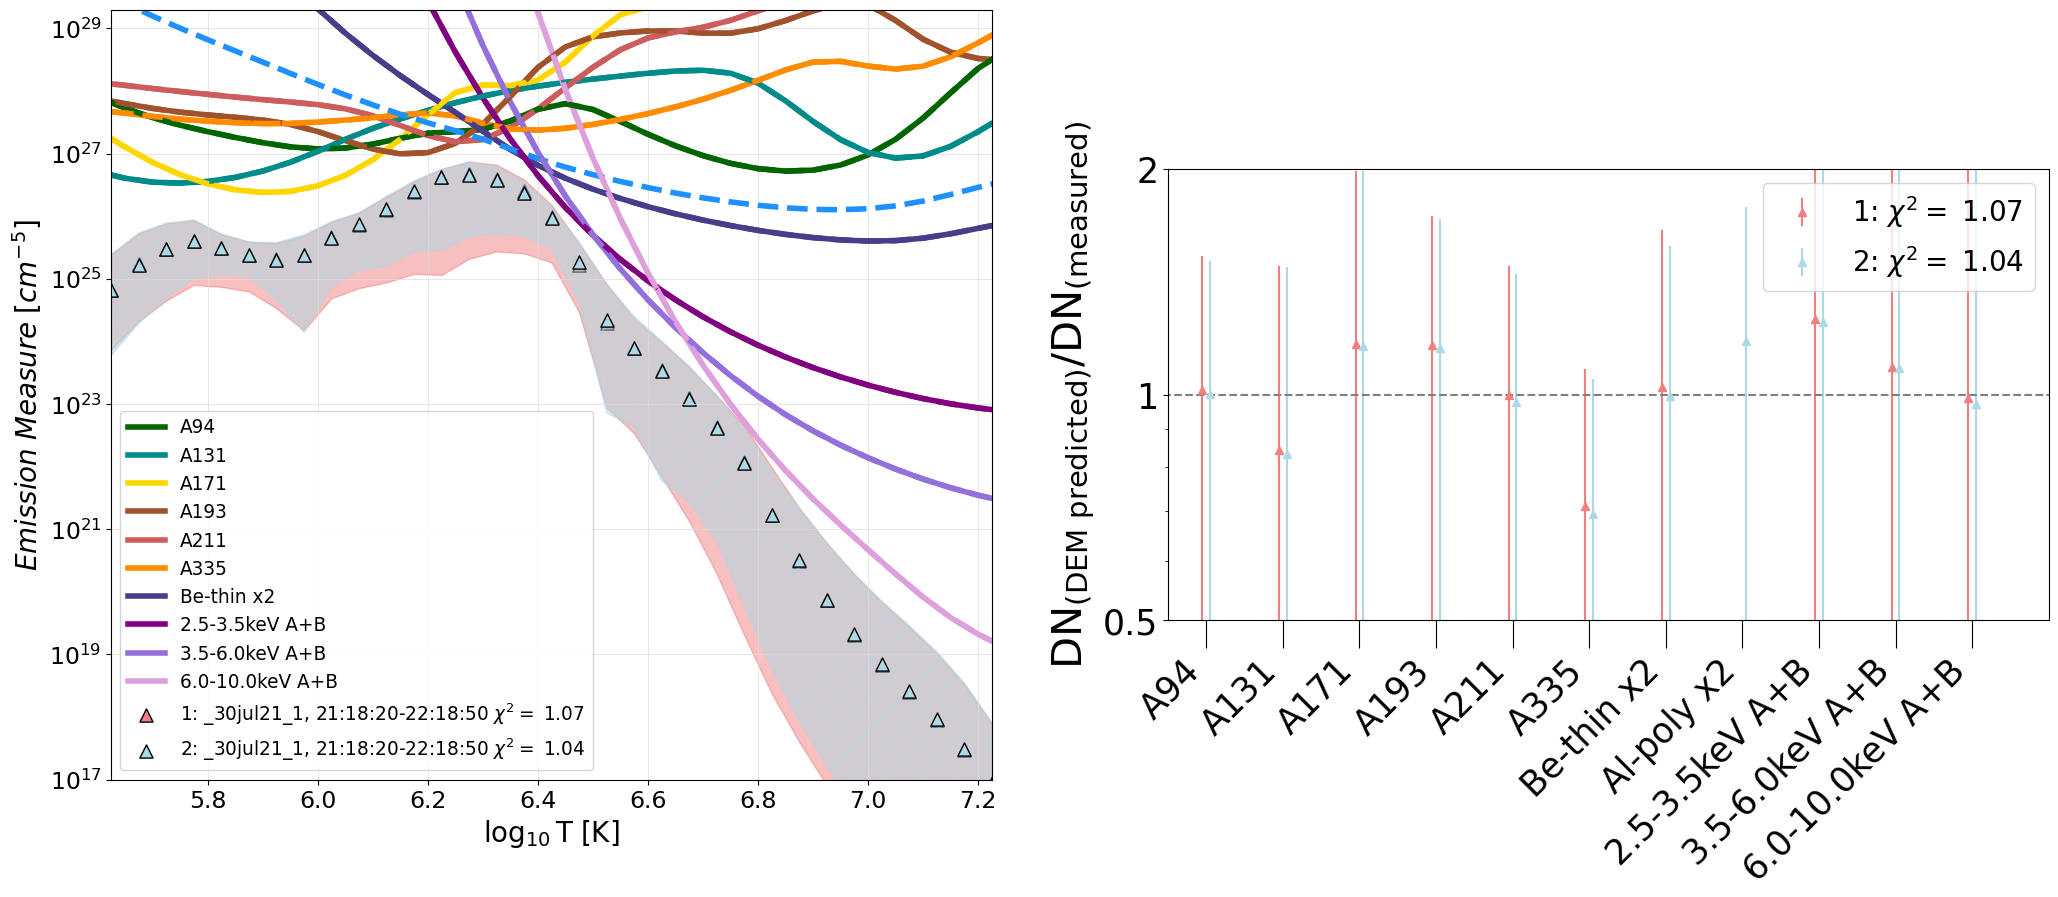

In [16]:
file = '/Users/jmdunca2/do-dem/DEM_folders//initial_dem_30jul21_1//west//21-18-20_22-18-50/21-18-20_22-18-50_5.6_7.2_30-jul-21_1ghost_corr_MC_DEM_result_withparams.pickle'
noalfile = '/Users/jmdunca2/do-dem/DEM_folders//initial_dem_30jul21_1//west//21-18-20_22-18-50/21-18-20_22-18-50_5.6_7.2_30-jul-21_1ghost_corr_no_Al-poly_MC_DEM_result.pickle'

pp = [file, noalfile]

labelfontsize=20

data1, timestring1, time1 = viz.load_DEM(pp[1])
data2, timestring2, time2 = viz.load_DEM(pp[0])
namest=pp[1].split('/')[6][11:]
namest2=pp[0].split('/')[6][11:]

fig = plt.figure(constrained_layout=True, figsize=(25,10))
gs = fig.add_gridspec(5, 2)
ax1 = fig.add_subplot(gs[0:5, 0])
ax2 = fig.add_subplot(gs[1:4, 1])


working_dir = '/Users/jmdunca2/do-dem/figures_etc/consistency_plots/'

importlib.reload(viz)


viz.compare_DEMs(data1, data2, timestring1, timestring2, title1=namest+', '+mod_timestring(timestring1), 
                 title2=namest2+', '+mod_timestring(timestring2), 
                 plotMK=False, plot=True, working_dir=working_dir, input_ax=ax1, input_ax2=ax2)

ax1.tick_params(axis='both', labelsize=17)
#ax1.set_title('Comparison - Two Quiescent Times on '+namest, fontsize=labelfontsize)
ax1.set_title('', fontsize=labelfontsize)

#ax2.set_title('Residuals', fontsize=labelfontsize)
ax2.set_title('', fontsize=labelfontsize)
ax1.set_ylim([1e17, 2e29])
ax1.legend(ncols=1, fontsize=labelfontsize/1.5)


['/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-15-15_18-22-40/18-15-15_18-22-40_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle', '/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-15-15_18-22-40/18-15-15_18-22-40_5.6_7.2_29-may-18_1no_Al-poly_MC_DEM_result.pickle']

['/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-22-40_18-23-40/18-22-40_18-23-40_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle', '/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-22-40_18-23-40/18-22-40_18-23-40_5.6_7.2_29-may-18_1no_Al-poly_MC_DEM_result.pickle']

['/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-23-40_18-24-20/18-23-40_18-24-20_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle', '/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-23-40_18-24-20/18-23-40_18-24-20_5.6_7.2_29-may-18_1no_Al-poly_MC_DEM_result.pickle']


/Users/jmdunca2/do-dem//dodem/visualize_dem_results.py:239: RuntimeWarning: divide by zero encountered in divide
  ax.semilogy(data1['ts_'],data1['dn_in'][i]/data1['trmatrix'][:,i],
/Users/jmdunca2/do-dem//dodem/visualize_dem_results.py:253: RuntimeWarning: divide by zero encountered in divide
  ax.semilogy(data2['ts_'],data2['dn_in'][i]/data2['trmatrix'][:,i],
/Users/jmdunca2/do-dem//dodem/visualize_dem_results.py:239: RuntimeWarning: divide by zero encountered in divide
  ax.semilogy(data1['ts_'],data1['dn_in'][i]/data1['trmatrix'][:,i],
/Users/jmdunca2/do-dem//dodem/visualize_dem_results.py:253: RuntimeWarning: divide by zero encountered in divide
  ax.semilogy(data2['ts_'],data2['dn_in'][i]/data2['trmatrix'][:,i],
/Users/jmdunca2/do-dem//dodem/visualize_dem_results.py:239: RuntimeWarning: divide by zero encountered in divide
  ax.semilogy(data1['ts_'],data1['dn_in'][i]/data1['trmatrix'][:,i],
/Users/jmdunca2/do-dem//dodem/visualize_dem_results.py:253: RuntimeWarning: divide by zero


['/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-24-20_18-25-20/18-24-20_18-25-20_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle', '/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-24-20_18-25-20/18-24-20_18-25-20_5.6_7.2_29-may-18_1no_Al-poly_MC_DEM_result.pickle']

['/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-25-20_18-26-15/18-25-20_18-26-15_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle', '/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-25-20_18-26-15/18-25-20_18-26-15_5.6_7.2_29-may-18_1no_Al-poly_MC_DEM_result.pickle']

['/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-26-15_18-27-00/18-26-15_18-27-00_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle', '/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-26-15_18-27-00/18-26-15_18-27-00_5.6_7.2_29-may-18_1no_Al-poly_MC_DEM_result.pickle']

['/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-27-00_18-29-15/18-27-00_18-29-15

/Users/jmdunca2/do-dem//dodem/visualize_dem_results.py:239: RuntimeWarning: divide by zero encountered in divide
  ax.semilogy(data1['ts_'],data1['dn_in'][i]/data1['trmatrix'][:,i],
/Users/jmdunca2/do-dem//dodem/visualize_dem_results.py:253: RuntimeWarning: divide by zero encountered in divide
  ax.semilogy(data2['ts_'],data2['dn_in'][i]/data2['trmatrix'][:,i],
/Users/jmdunca2/do-dem//dodem/visualize_dem_results.py:239: RuntimeWarning: divide by zero encountered in divide
  ax.semilogy(data1['ts_'],data1['dn_in'][i]/data1['trmatrix'][:,i],
/Users/jmdunca2/do-dem//dodem/visualize_dem_results.py:253: RuntimeWarning: divide by zero encountered in divide
  ax.semilogy(data2['ts_'],data2['dn_in'][i]/data2['trmatrix'][:,i],
/Users/jmdunca2/do-dem//dodem/visualize_dem_results.py:239: RuntimeWarning: divide by zero encountered in divide
  ax.semilogy(data1['ts_'],data1['dn_in'][i]/data1['trmatrix'][:,i],
/Users/jmdunca2/do-dem//dodem/visualize_dem_results.py:253: RuntimeWarning: divide by zero

/Users/jmdunca2/miniforge3/lib/python3.10/site-packages/IPython/core/pylabtools.py:152: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


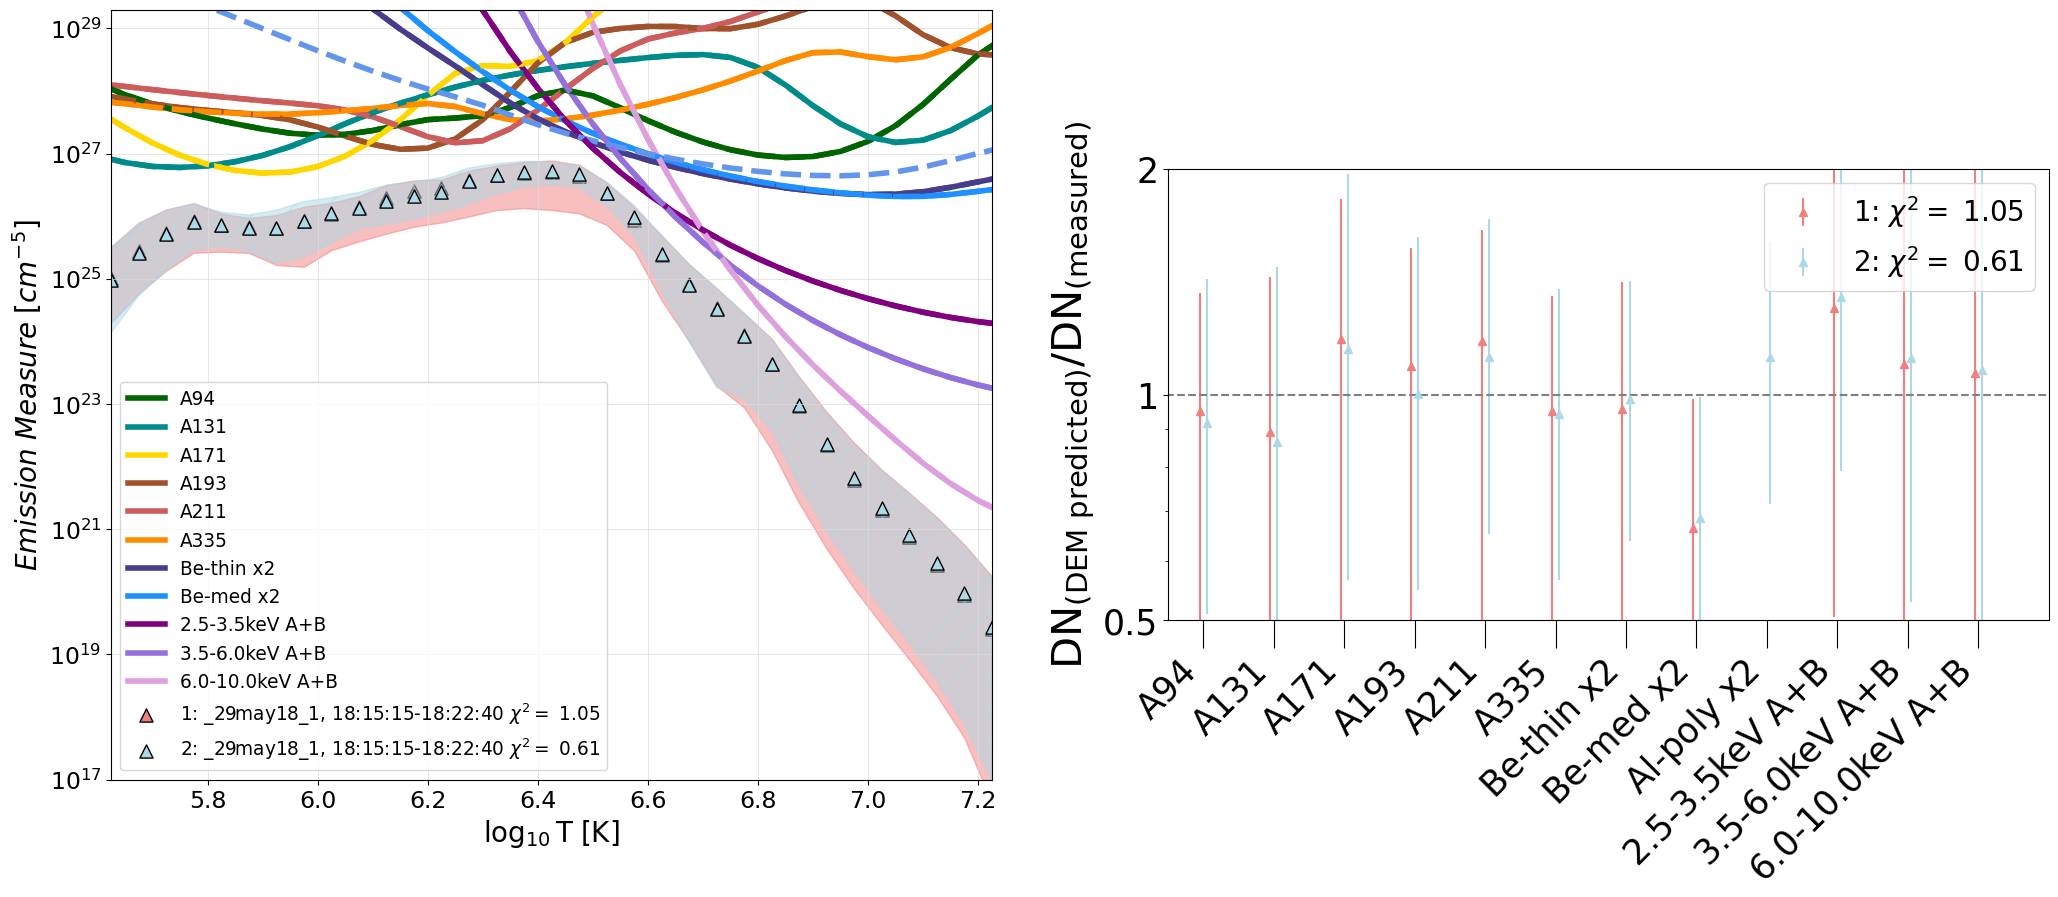

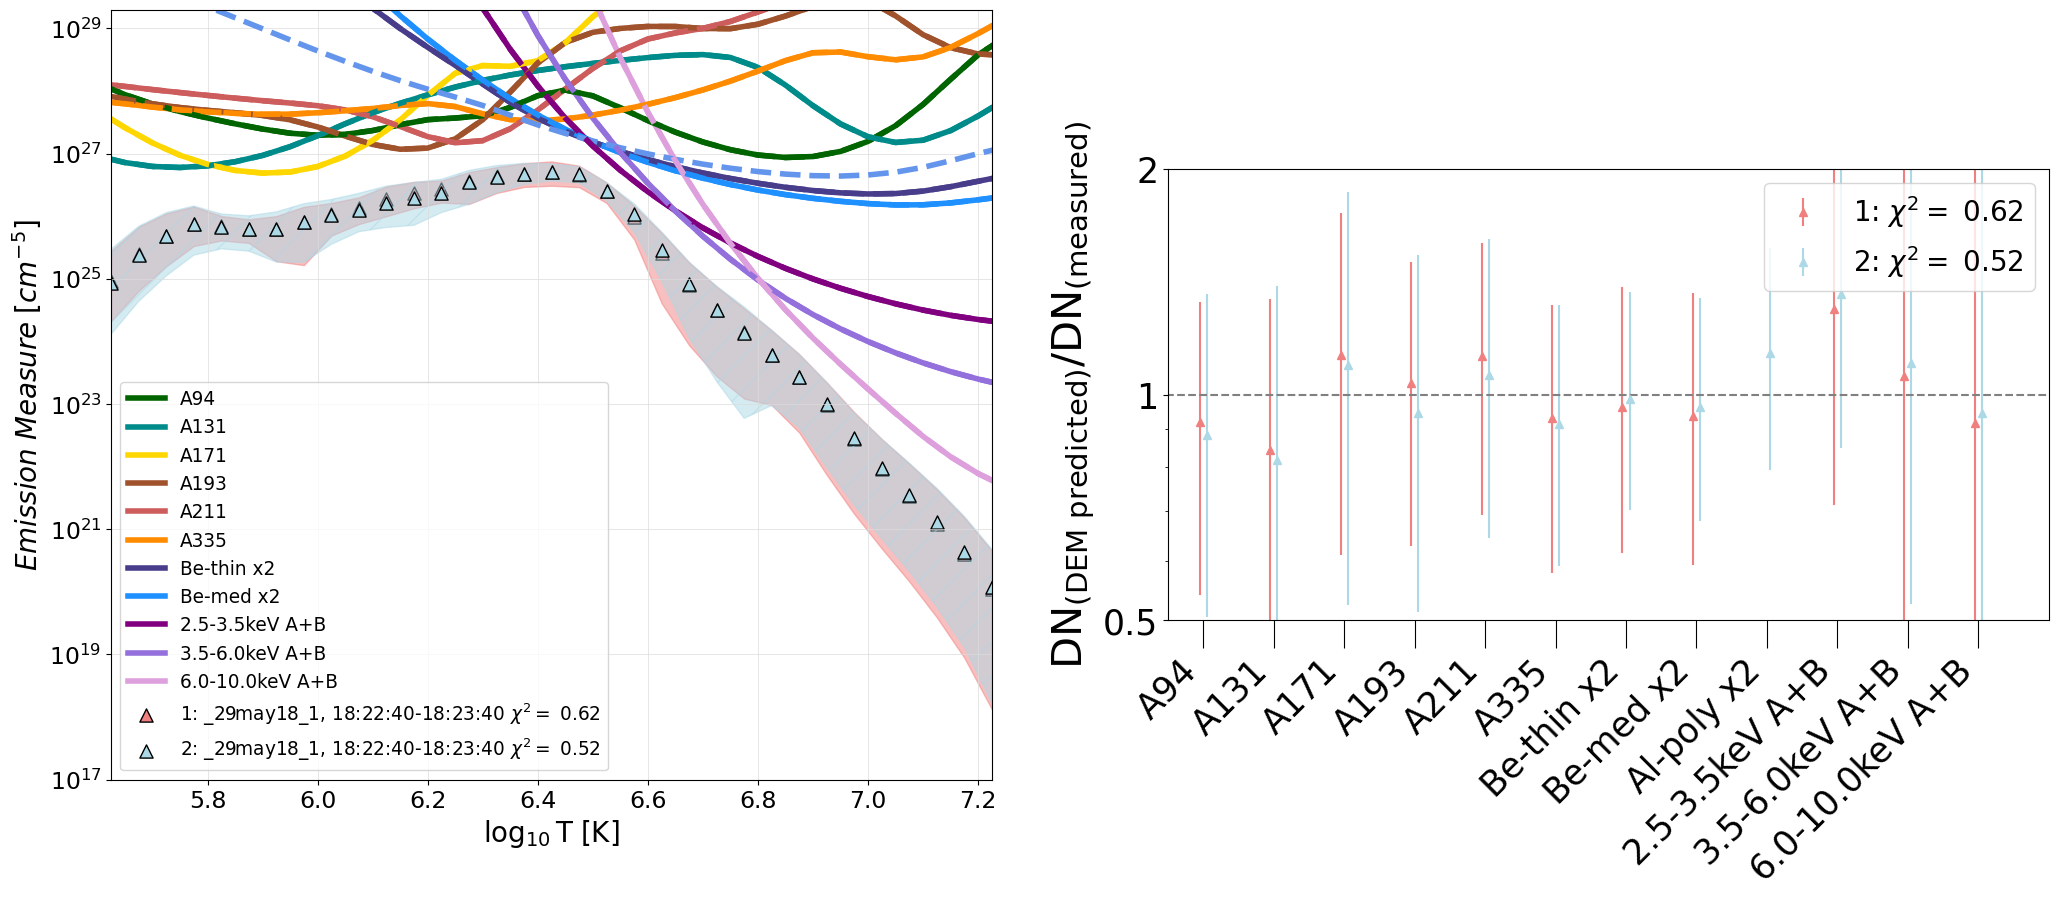

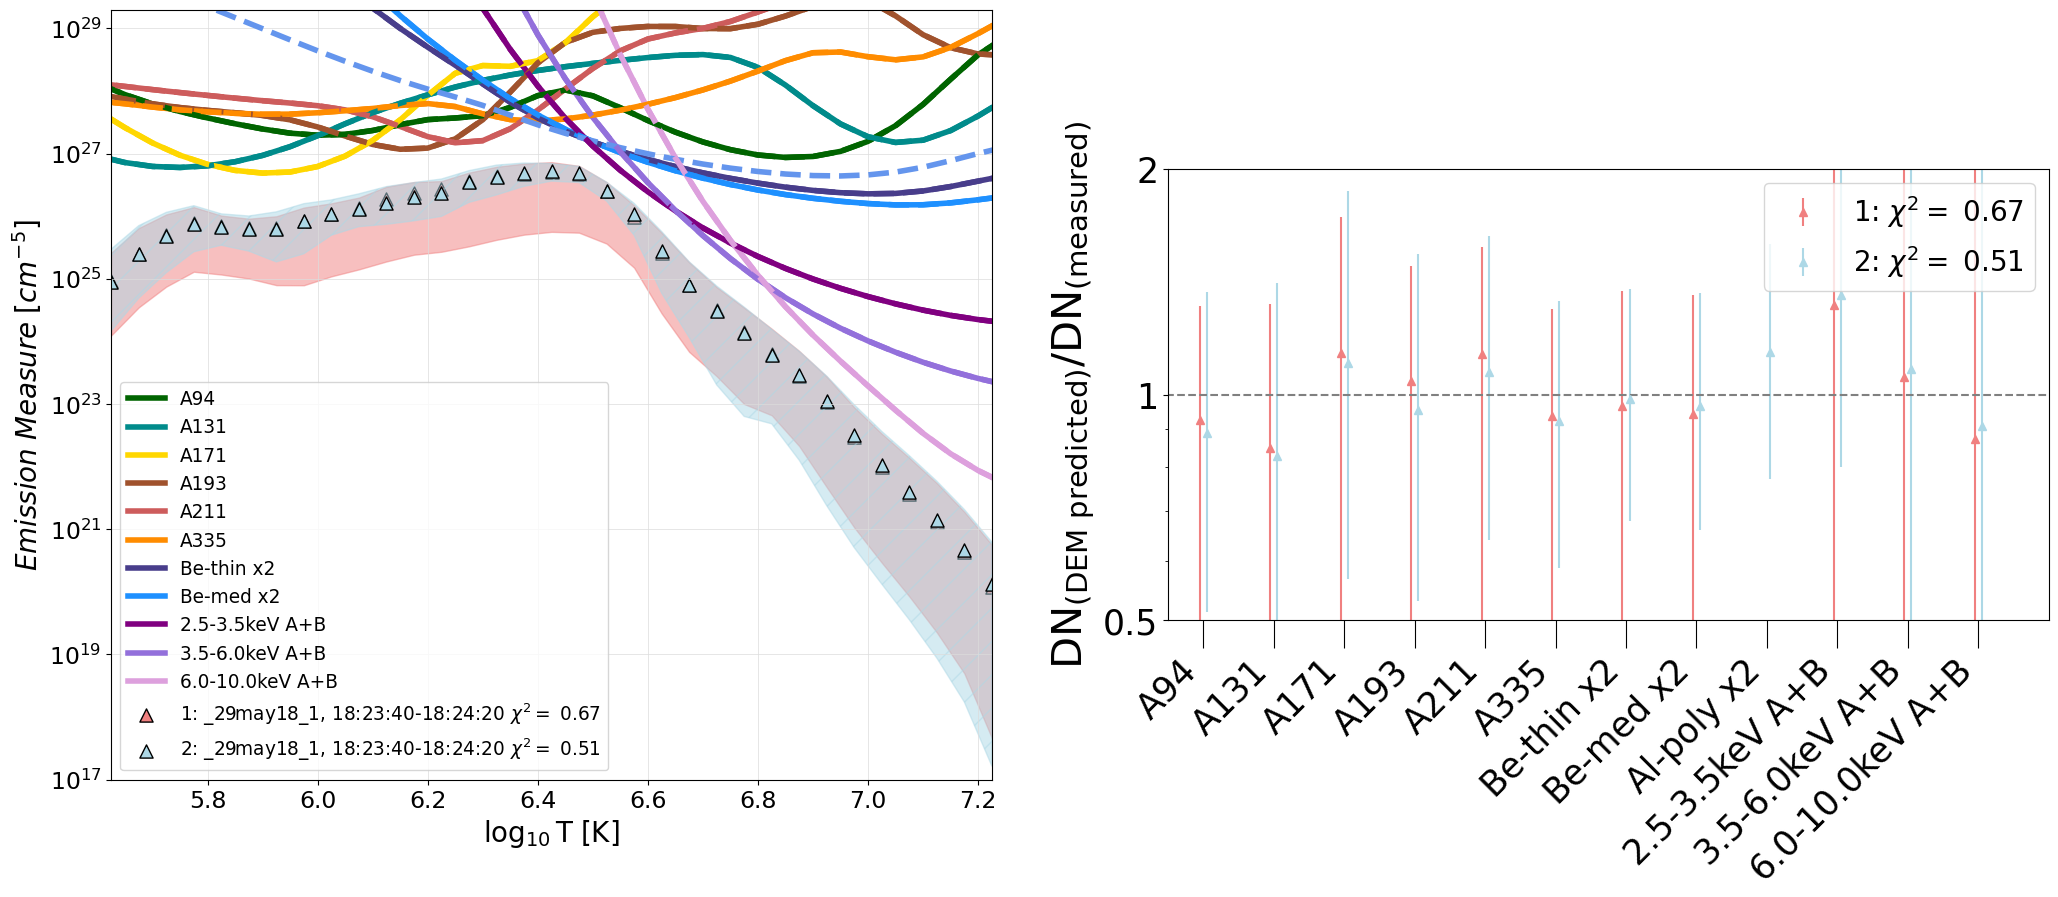

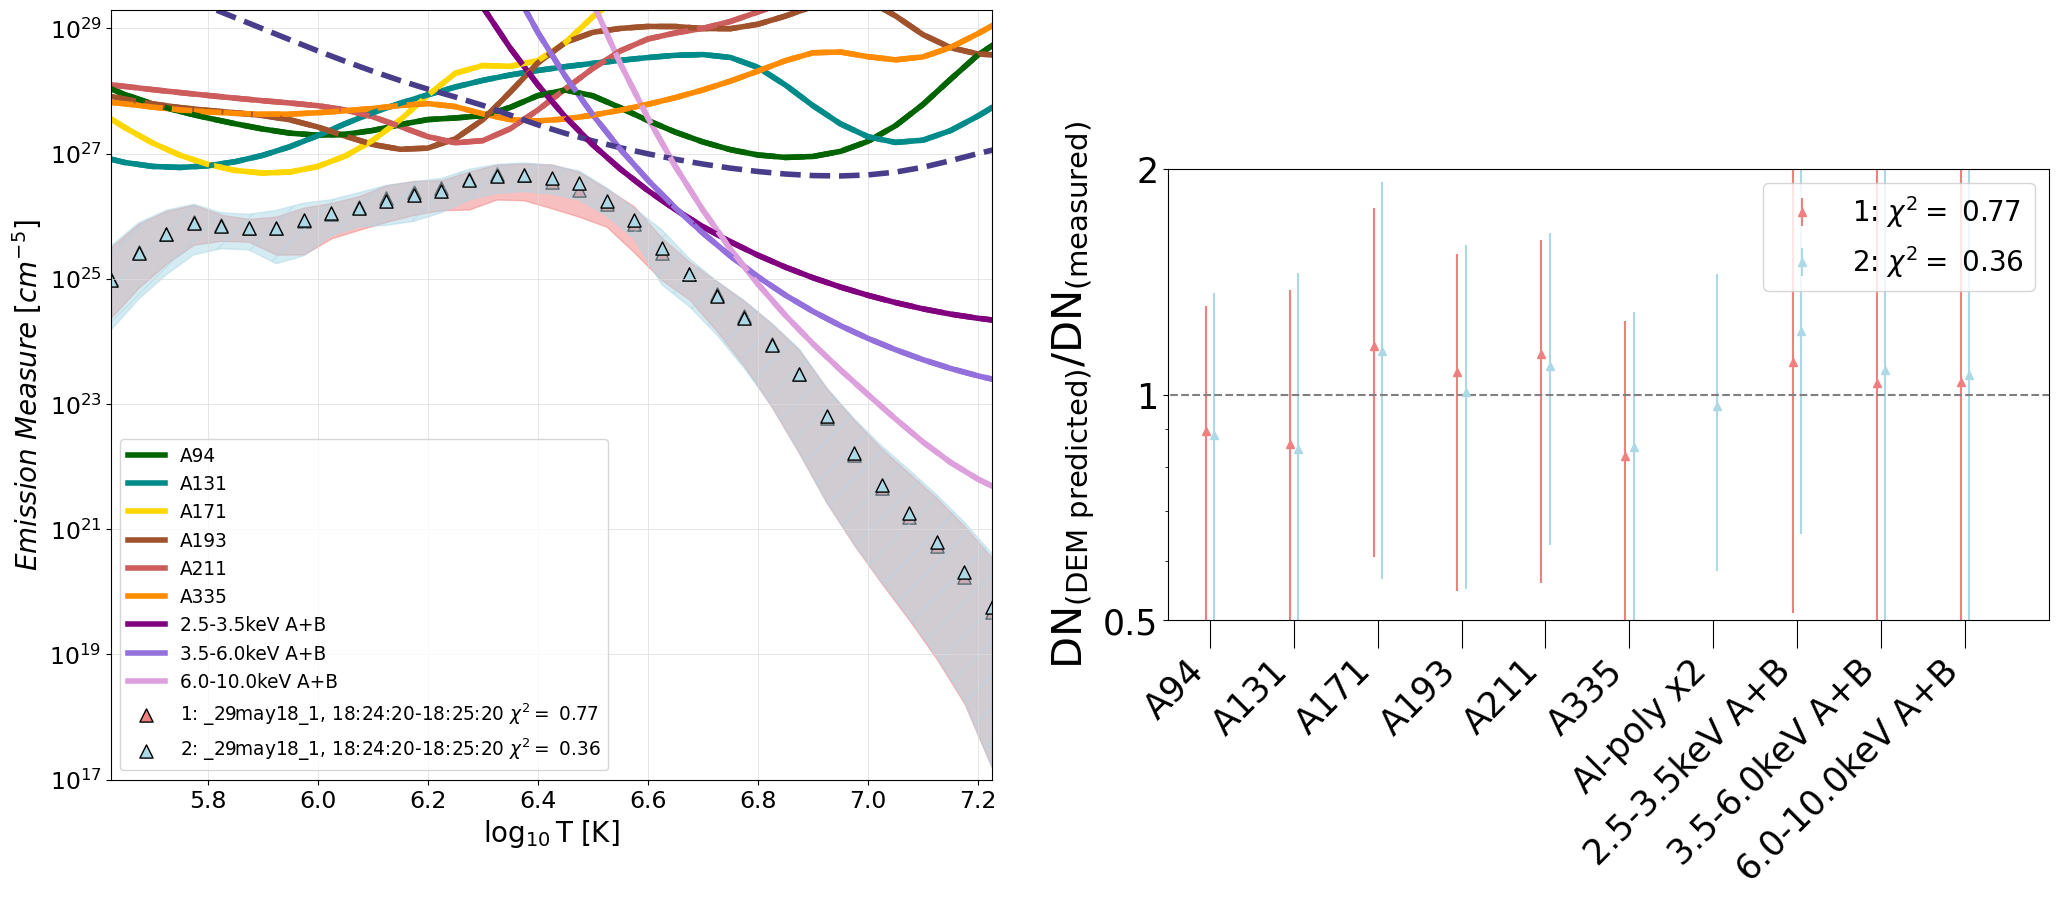

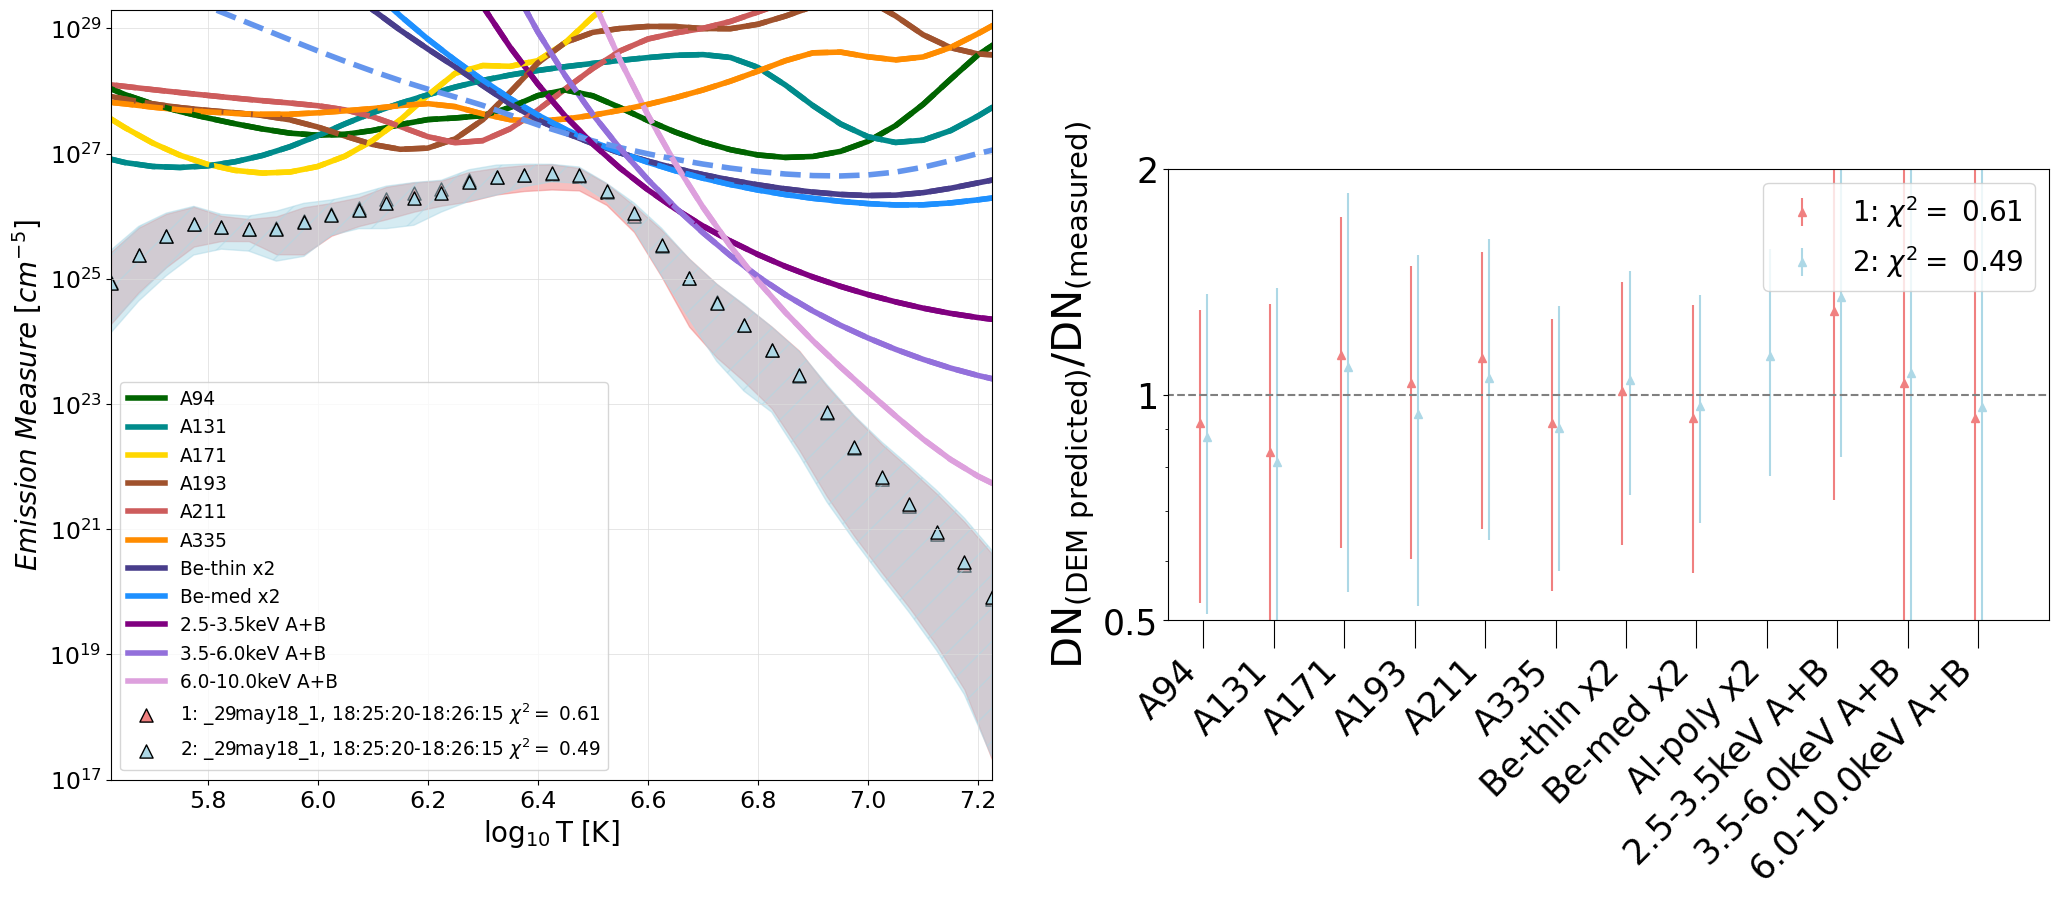

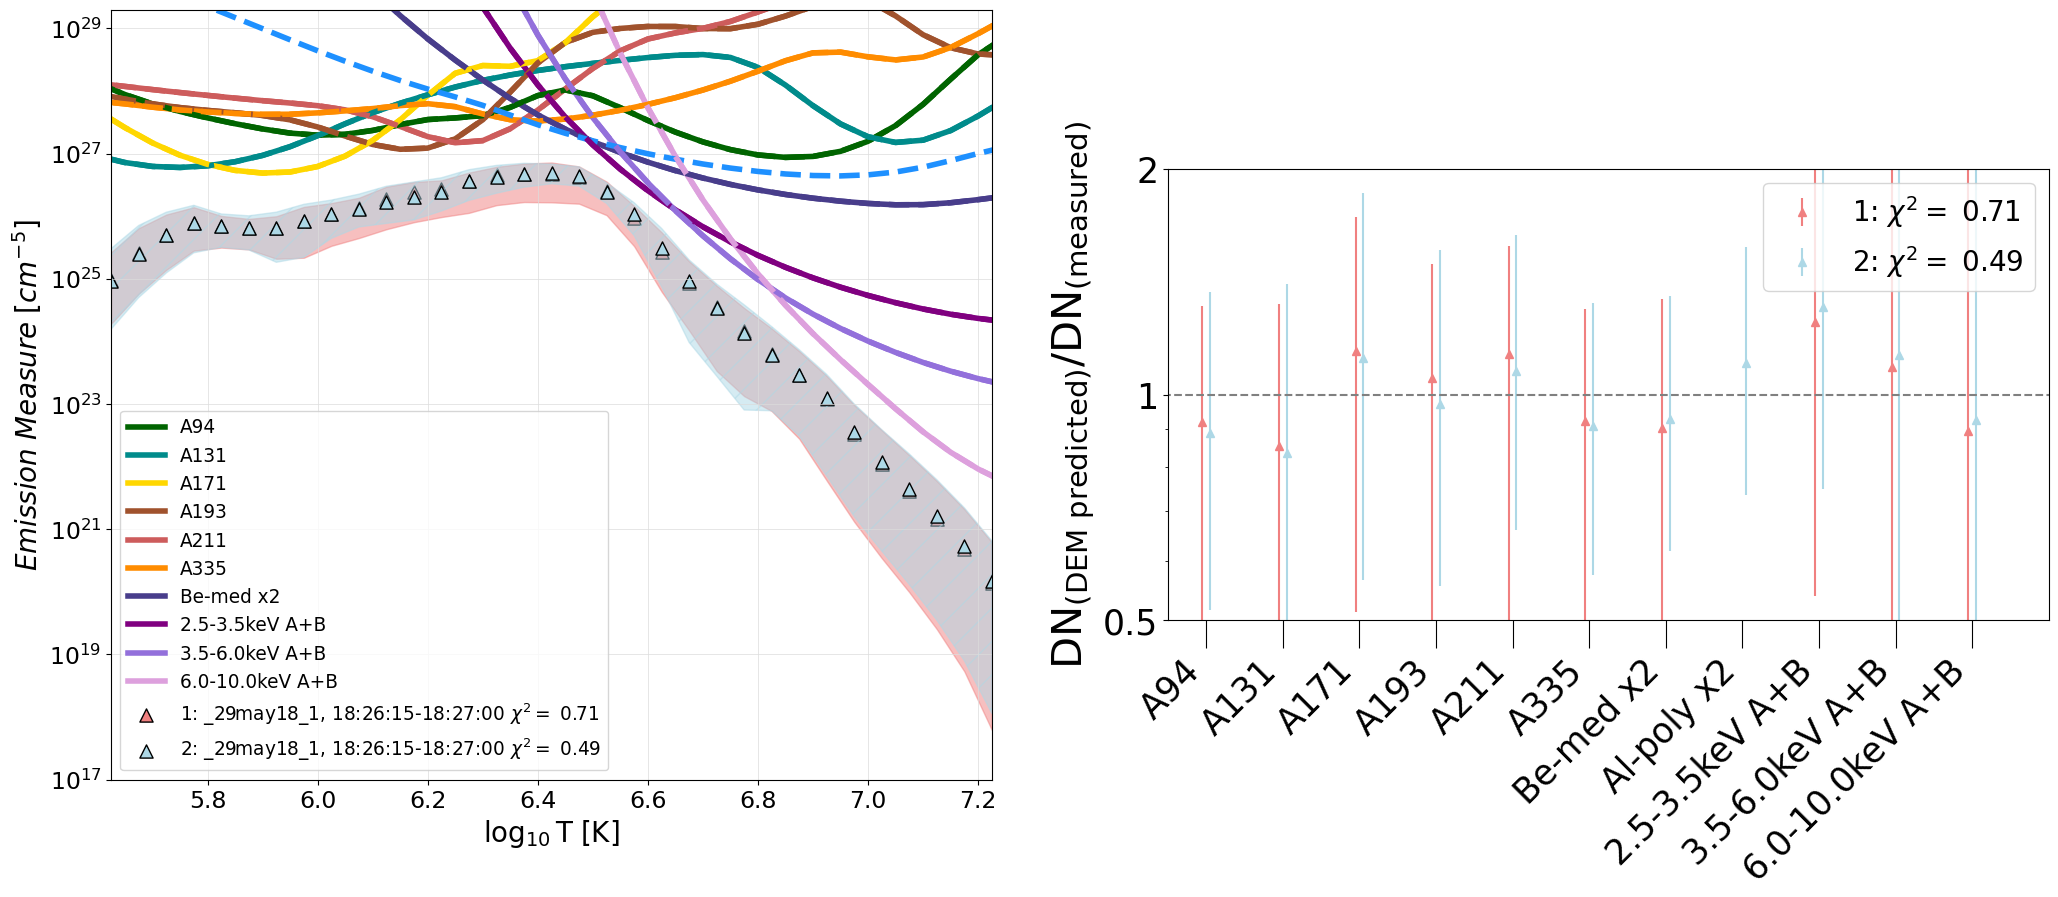

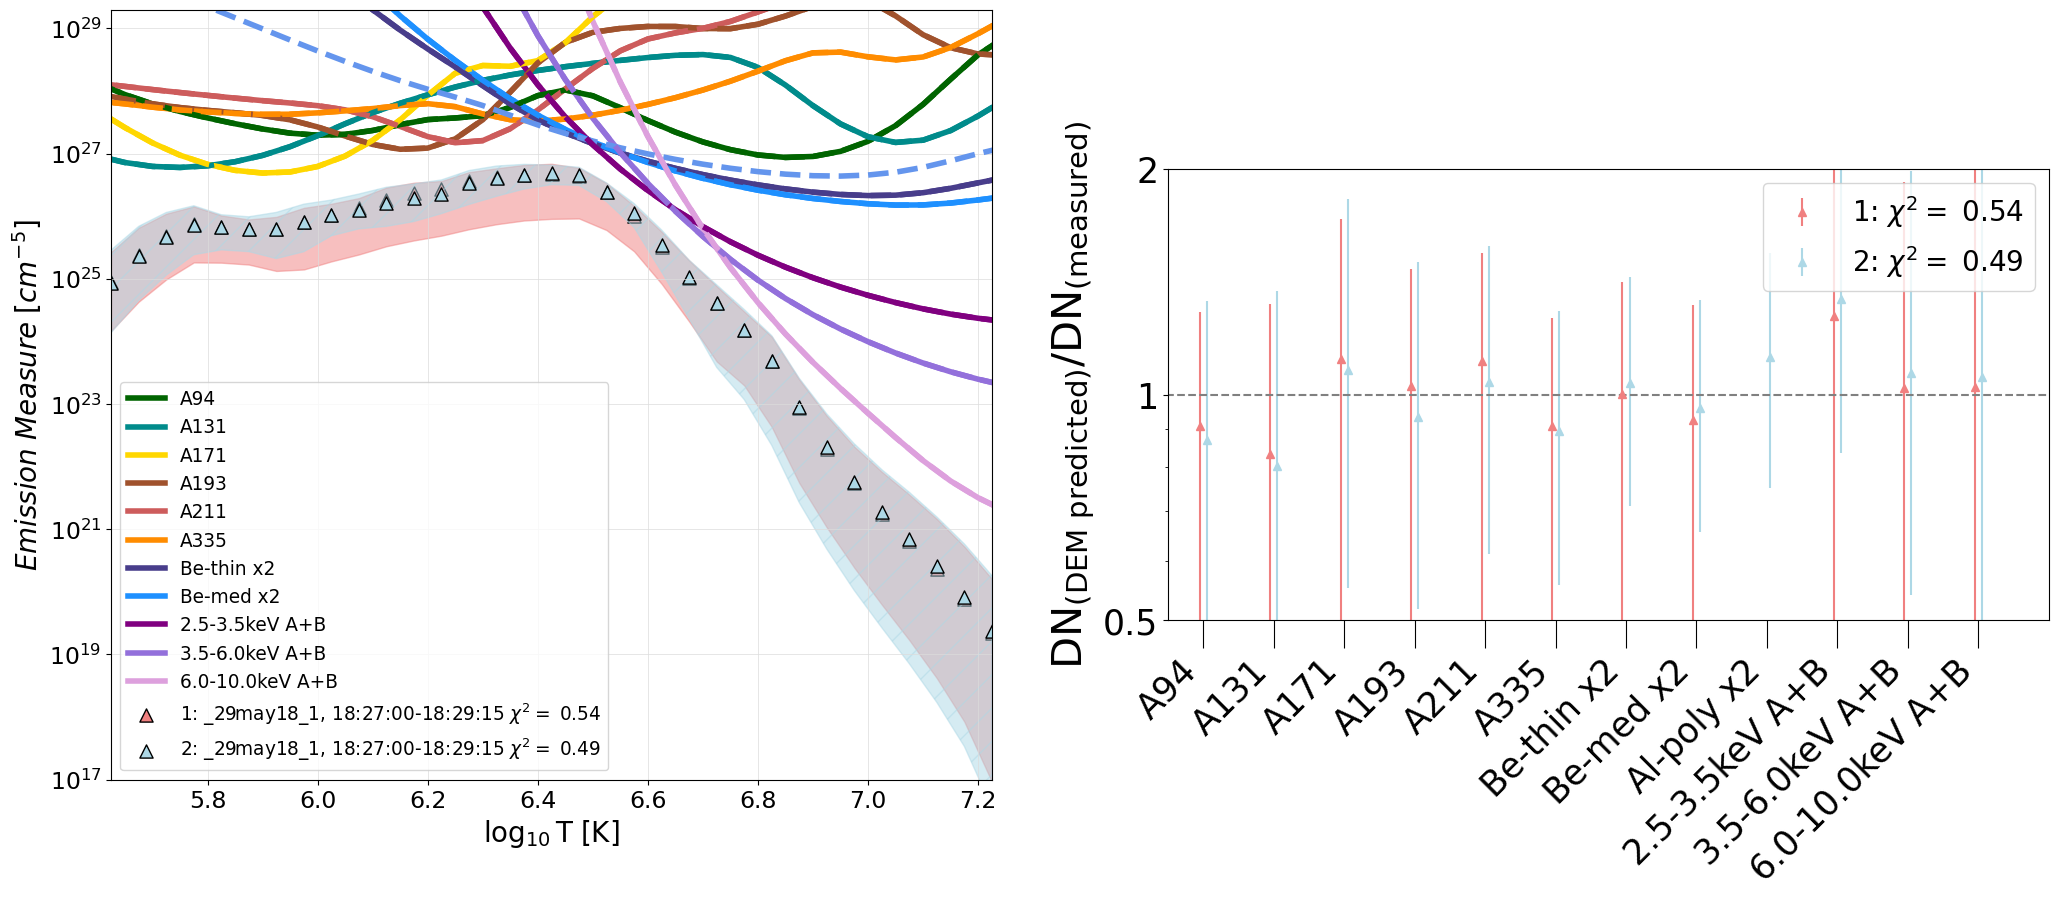

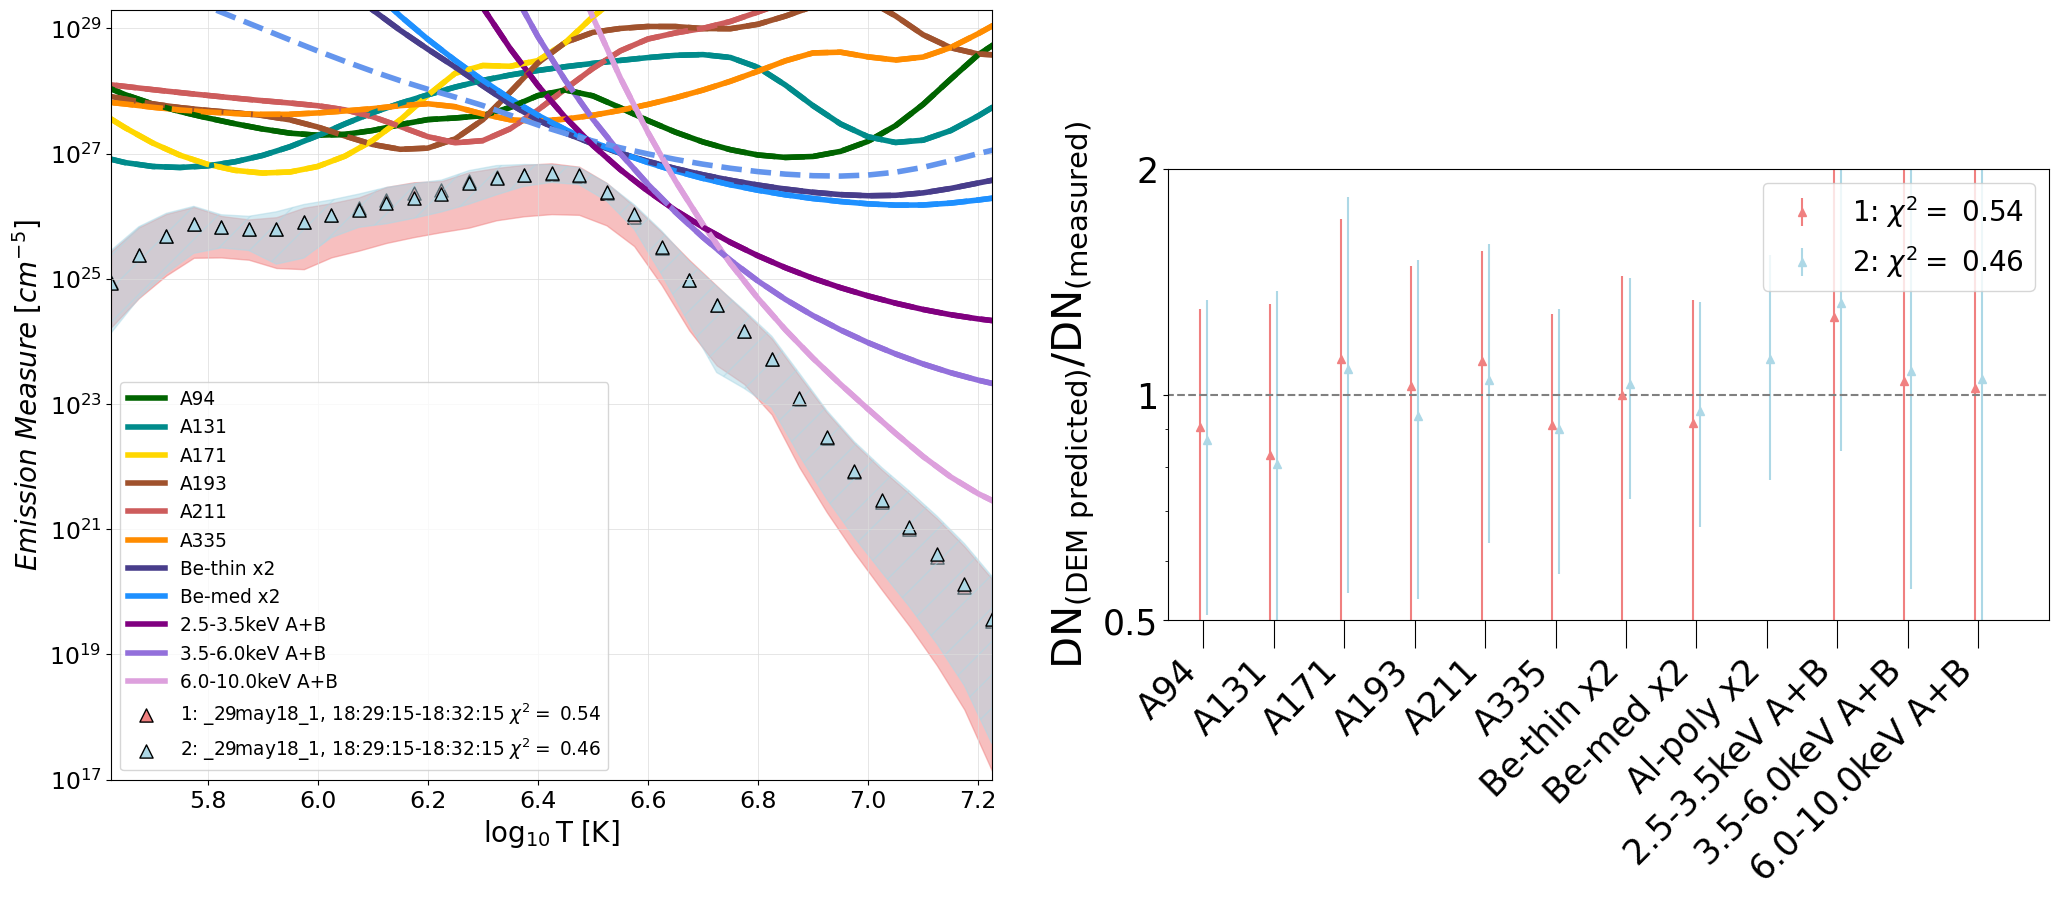

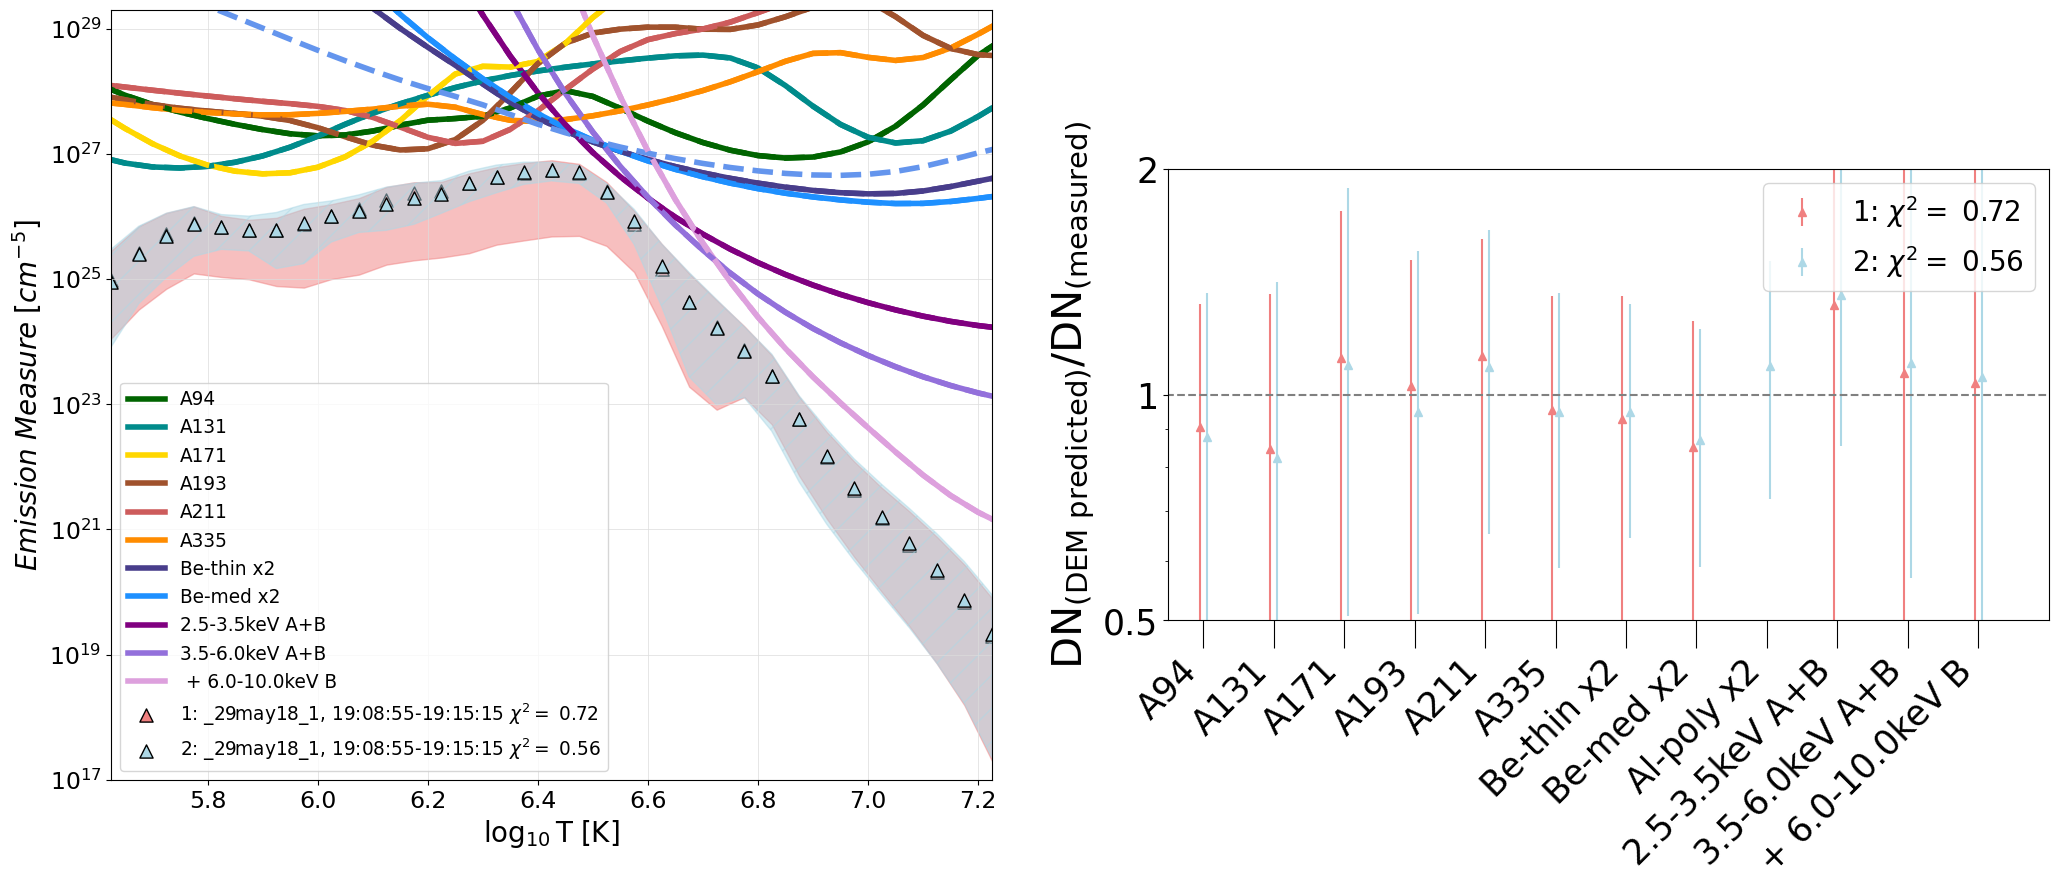

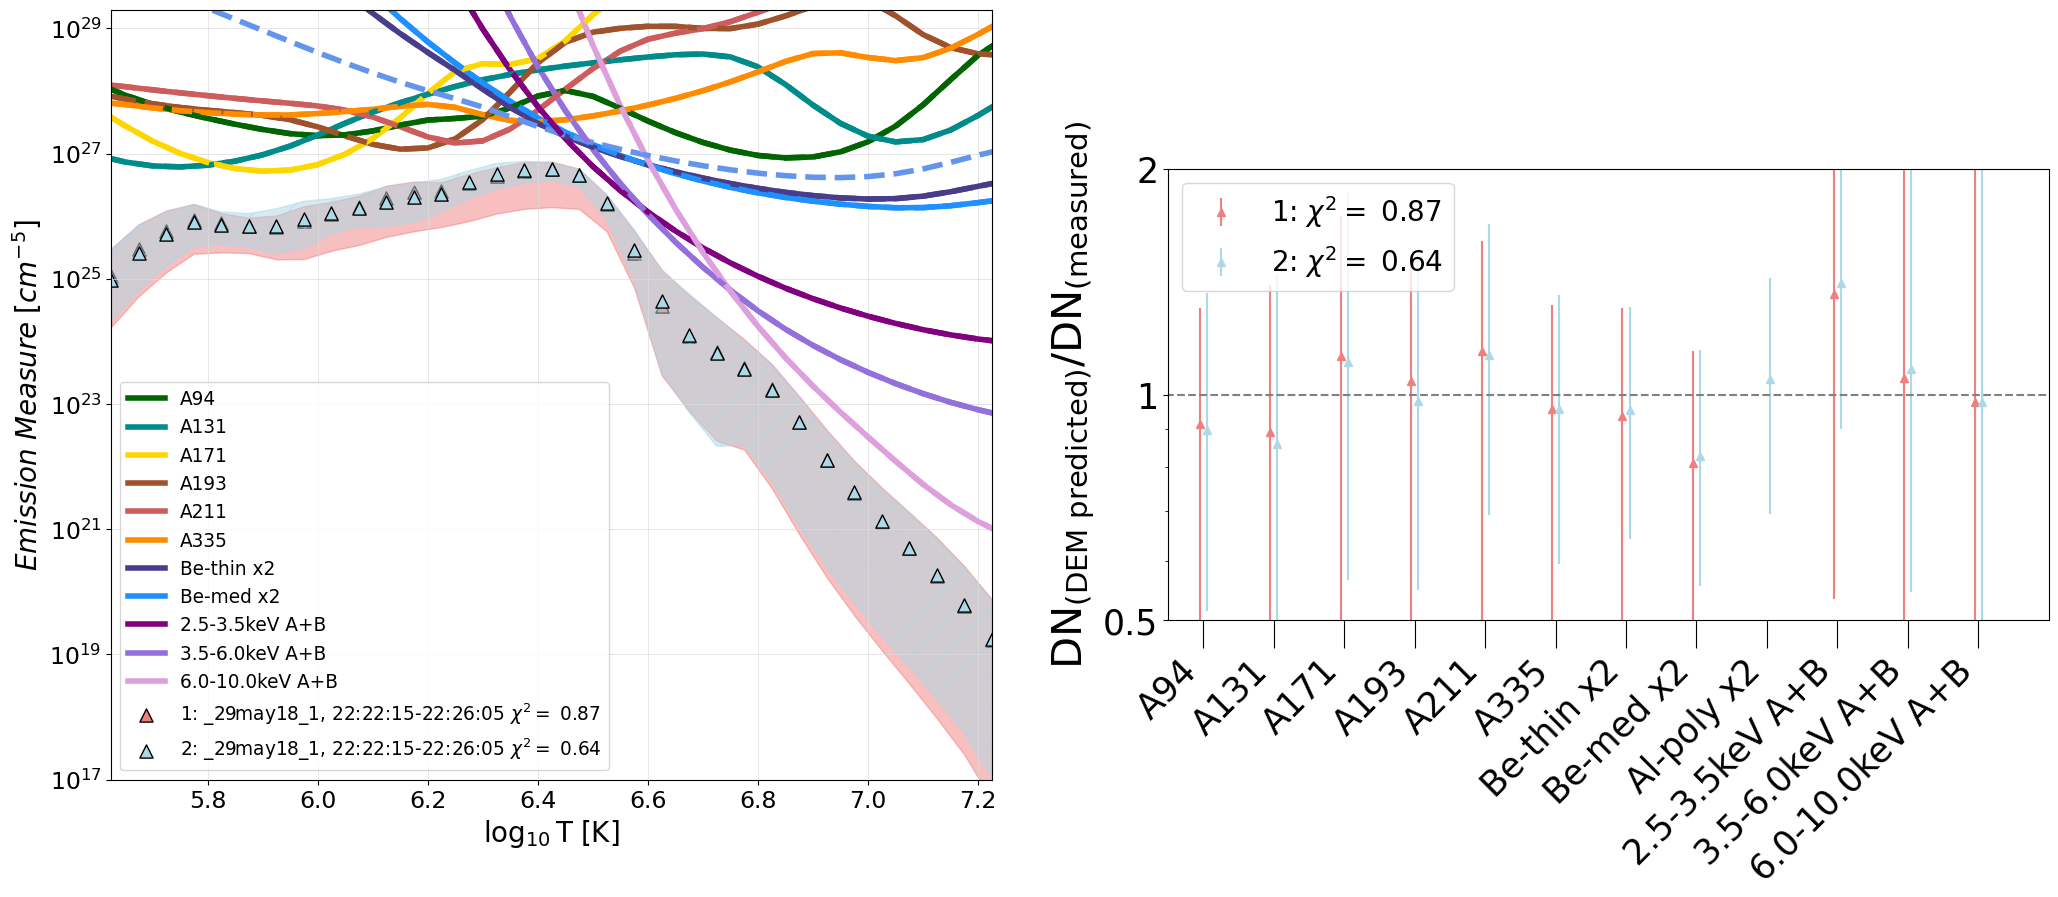

In [25]:
files = ['/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-15-15_18-22-40/18-15-15_18-22-40_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle',
'/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-22-40_18-23-40/18-22-40_18-23-40_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle',
'/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-23-40_18-24-20/18-23-40_18-24-20_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle',
'/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-24-20_18-25-20/18-24-20_18-25-20_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle',
'/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-25-20_18-26-15/18-25-20_18-26-15_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle',
'/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-26-15_18-27-00/18-26-15_18-27-00_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle',
'/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-27-00_18-29-15/18-27-00_18-29-15_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle',
'/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-29-15_18-32-15/18-29-15_18-32-15_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle',
'/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//19-08-55_19-15-15/19-08-55_19-15-15_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle',
'/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//22-22-15_22-26-05/22-22-15_22-26-05_5.6_7.2_29-may-18_1_MC_DEM_result_withparams.pickle']


noalfiles = ['/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-15-15_18-22-40/18-15-15_18-22-40_5.6_7.2_29-may-18_1no_Al-poly_MC_DEM_result.pickle',
'/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-22-40_18-23-40/18-22-40_18-23-40_5.6_7.2_29-may-18_1no_Al-poly_MC_DEM_result.pickle',
'/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-23-40_18-24-20/18-23-40_18-24-20_5.6_7.2_29-may-18_1no_Al-poly_MC_DEM_result.pickle',
'/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-24-20_18-25-20/18-24-20_18-25-20_5.6_7.2_29-may-18_1no_Al-poly_MC_DEM_result.pickle',
'/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-25-20_18-26-15/18-25-20_18-26-15_5.6_7.2_29-may-18_1no_Al-poly_MC_DEM_result.pickle',
'/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-26-15_18-27-00/18-26-15_18-27-00_5.6_7.2_29-may-18_1no_Al-poly_MC_DEM_result.pickle',
'/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-27-00_18-29-15/18-27-00_18-29-15_5.6_7.2_29-may-18_1no_Al-poly_MC_DEM_result.pickle',
'/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//18-29-15_18-32-15/18-29-15_18-32-15_5.6_7.2_29-may-18_1no_Al-poly_MC_DEM_result.pickle',
'/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//19-08-55_19-15-15/19-08-55_19-15-15_5.6_7.2_29-may-18_1no_Al-poly_MC_DEM_result.pickle',
'/Users/jmdunca2/do-dem/DEM_folders//initial_dem_29may18_1//22-22-15_22-26-05/22-22-15_22-26-05_5.6_7.2_29-may-18_1no_Al-poly_MC_DEM_result.pickle']


filepairs = [[files[i], noalfiles[i]] for i in range(0, len(files))]

labelfontsize=20

for pp in filepairs:

    print(pp)
    data1, timestring1, time1 = viz.load_DEM(pp[1])
    data2, timestring2, time2 = viz.load_DEM(pp[0])
    namest=pp[1].split('/')[6][11:]
    namest2=pp[0].split('/')[6][11:]

    fig = plt.figure(constrained_layout=True, figsize=(25,10))
    gs = fig.add_gridspec(5, 2)
    ax1 = fig.add_subplot(gs[0:5, 0])
    ax2 = fig.add_subplot(gs[1:4, 1])

    
    working_dir = '/Users/jmdunca2/do-dem/figures_etc/consistency_plots/'

    importlib.reload(viz)


    viz.compare_DEMs(data1, data2, timestring1, timestring2, title1=namest+', '+mod_timestring(timestring1), 
                     title2=namest2+', '+mod_timestring(timestring2), 
                     plotMK=False, plot=True, working_dir=working_dir, input_ax=ax1, input_ax2=ax2)
    
    ax1.tick_params(axis='both', labelsize=17)
    #ax1.set_title('Comparison - Two Quiescent Times on '+namest, fontsize=labelfontsize)
    ax1.set_title('', fontsize=labelfontsize)

    #ax2.set_title('Residuals', fontsize=labelfontsize)
    ax2.set_title('', fontsize=labelfontsize)
    ax1.set_ylim([1e17, 2e29])
    ax1.legend(ncols=1, fontsize=labelfontsize/1.5)
    print('')
